# Лабораторная работа № 5

## Конфигурационное пространство и прямая задача кинематики

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 6. Конфигурационное пространство и прямая задача кинематики манипулятора

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Освоить два способа описания кинематической цепи — параметры Денавита — Хартенберга
и представление произведением экспонент, — убедиться в их эквивалентности,
и научиться оценивать рабочую зону манипулятора методом Монте-Карло.

### Что понадобится

`numpy`, `sympy`, `matplotlib`.

### Правило практикума

Алгоритм вы реализуете сами. Готовые пакеты робототехники (`roboticstoolbox`,
`spatialmath`) допустимо использовать **только** для сверки — и такую сверку
нужно показать явно.

## Теоретическая справка

### Кинематическая цепь и конфигурационное пространство

Манипулятор — цепь жёстких звеньев, соединённых сочленениями. Каждое вращательное
сочленение добавляет одну степень свободы, и набор всех углов $q = (q_1,\dots,q_n)$
задаёт **конфигурацию**.

Множество всех конфигураций называется конфигурационным пространством. Для цепи
из $n$ вращательных сочленений это тор $T^n = S^1 \times \dots \times S^1$: каждый
угол определён по модулю $2\pi$. Заметьте, что это не $\mathbb{R}^n$ — и по той же
причине, что обсуждалась в лекции 3, тор нельзя гладко и взаимно однозначно
отобразить на $\mathbb{R}^n$.

**Прямая задача кинематики** — это отображение

$$f:\ T^n \to SE(3), \qquad q \mapsto T(q),$$

сопоставляющее конфигурации позу схвата. Оно всегда однозначно и вычисляется явно;
обратное отображение неоднозначно и явной формулы в общем случае не имеет — этим
займёмся в теме 7.

### Параметры Денавита — Хартенберга

Переход между соседними звеньями задаётся четырьмя числами вместо шести: если
оси координат выбраны по специальному правилу, преобразование раскладывается в

$$T_i = R_z(\theta_i)\, T_z(d_i)\, T_x(a_i)\, R_x(\alpha_i).$$

Здесь $a_i$ — длина звена, $\alpha_i$ — угол скрещивания осей, $d_i$ — смещение
вдоль оси, $\theta_i$ — угол поворота. У вращательного сочленения переменная
величина — $\theta_i$, остальные три постоянны.

Полная кинематика — произведение вдоль цепи, ровно как дерево координат из лекции 2:

$$T(q) = T_1(q_1)\, T_2(q_2)\, \dots\, T_n(q_n).$$

### Представление произведением экспонент

Альтернатива, не требующая специального выбора осей. Каждому сочленению
сопоставляется винтовая ось $S_i = (\omega_i,\, v_i)$, где $\omega_i$ — единичный
вектор оси, а $v_i = -\omega_i \times q_i$ для точки $q_i$ на оси. Тогда

$$T(q) = e^{[S_1]q_1}\, e^{[S_2]q_2} \cdots e^{[S_n]q_n} \cdot M,$$

где $M$ — поза схвата в нулевой конфигурации. Матричная экспонента для $se(3)$
вычисляется в замкнутой форме — это прямое обобщение формулы Родрига из лекции 3.

### Рабочая зона и метод Монте-Карло

Рабочая зона — образ конфигурационного пространства при отображении $f$. Для
плоского 2R-манипулятора это кольцо с радиусами $|l_1 - l_2|$ и $l_1 + l_2$,
площадь которого равна $4\pi l_1 l_2$ — редкий случай, когда ответ известен точно
и с ним можно сверить численную оценку.

Метод Монте-Карло даёт погрешность порядка $N^{-1/2}$ независимо от размерности —
именно поэтому в шестимерном случае он остаётся практически единственным способом.

In [1]:
import numpy as np
import sympy as sp
import time
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

# параметры UR5: (a, alpha, d) для шести звеньев, метры и радианы
UR5 = [(0.0,      np.pi / 2,  0.089159),
       (-0.425,   0.0,        0.0),
       (-0.39225, 0.0,        0.0),
       (0.0,      np.pi / 2,  0.10915),
       (0.0,     -np.pi / 2,  0.09465),
       (0.0,      0.0,        0.0823)]

## Задание 1. Матрица Денавита — Хартенберга

Реализуйте `dh(a, alpha, d, theta, lib)` по формуле из справки. Параметр `lib`
позволит одной и той же функцией считать и численно (`numpy`), и символьно (`sympy`) —
это понадобится в заданиях 2 и 3.

**Контроль.** Для $a = 0{,}5$, $\alpha = 0$, $d = 0$, $\theta = 90°$ схват должен
оказаться в точке $(0;\ 0{,}5;\ 0)$. Проверьте также $\det R = 1$
и $\|R^{\mathsf T}R - I\|$ на уровне машинной погрешности.

**Вопрос для вывода:** почему для перехода между звеньями хватает четырёх чисел,
хотя элемент $SE(3)$ задаётся шестью?

In [89]:
# ============================================================
# ЗАДАНИЕ 1. Матрица Денавита — Хартенберга
# Соглашение классическое, как в теоретической справке:
#     T = R_z(theta) * T_z(d) * T_x(a) * R_x(alpha)
# ============================================================

def dh(a, alpha, d, theta, lib=np):
    """Матрица перехода от звена i-1 к звену i (параметры DH).

    a     -- длина звена:      сдвиг вдоль оси x_i
    alpha -- угол скрещивания: поворот вокруг оси x_i
    d     -- смещение звена:   сдвиг вдоль оси z_{i-1}
    theta -- угол сочленения:  поворот вокруг оси z_{i-1}
    lib   -- np (считать численно) или sp (считать символьно)
    """
    # Тригонометрия берётся из переданной библиотеки: lib=np вернёт
    # числа, lib=sp вернёт формулы (если аргументы -- символы).
    ct = lib.cos(theta)    # cos(theta)
    st = lib.sin(theta)    # sin(theta)
    ca = lib.cos(alpha)    # cos(alpha)
    sa = lib.sin(alpha)    # sin(alpha)

    # Явный вид произведения R_z(theta)*T_z(d)*T_x(a)*R_x(alpha)
    # из теоретической справки (одинаков для обеих библиотек):
    
    T = [[ct, -st * ca,  st * sa, a * ct],   # строка 1
         [st,  ct * ca, -ct * sa, a * st],   # строка 2
         [0,   sa,       ca,      d     ],   # строка 3: theta не входит
         [0,   0,        0,       1     ]]   # строка 4: однородные координаты

    # Из списка строк собираем матрицу выбранной библиотеки:
    if lib is sp:          # символьный режим: SymPy хранит формулы
        return sp.Matrix(T)
    return np.array(T)     # численный режим: NumPy хранит числа


# ---------- Контроль из методички (численный режим, numpy) ----------
# a = 0.5, alpha = 0, d = 0, theta = 90 градусов.
# Углы везде задаются в радианах: 90° = pi/2 ~ 1.5708.
T1 = dh(a=0.5, alpha=0.0, d=0.0, theta=np.pi / 2, lib=np)
print("T =")
print(T1)

R = T1[:3, :3]   # верхний левый блок 3x3 -- матрица поворота
p = T1[:3, 3]    # верхние три элемента последнего столбца -- позиция схвата
print("\nПозиция схвата p =", p)                              # (0, 0.5, 0)
print("det R =", np.linalg.det(R)) # 1.0

print("||R^T R - I|| =", np.linalg.norm(R.T @ R - np.eye(3)))  # ~1e-16

# ---------- Та же функция в символьном режиме (sympy) ----------
q = sp.symbols('q')                             # угол как символ (буква)
T_sym = dh(sp.Rational(1, 2), 0, 0, q, lib=sp)  # a = 1/2 -- точная дробь
T_90 = T_sym.subs(q, sp.pi / 2)                 # подставляем ТОЧНОЕ pi/2
print("\nСимвольная матрица при theta = pi/2:")
print(T_90)
print("Позиция (точно):", T_90[:3, 3].T)    # (0, 1/2, 0) без погрешности
# ВАЖНО: именно sp.pi/2, а не np.pi/2! SymPy не знает, что np.pi/2 --
# это pi/2: sp.cos(np.pi/2) = 6.1e-17 (число, не 0), и упрощений не будет
# (это критично в задании 3).

# ---------- Самопроверка: верен ли порядок сомножителей ----------
# В контроле методички d = 0 и alpha = 0, поэтому T_z и R_x вырождаются
# в единичные матрицы, и не всякая ошибка порядка там заметна. Проверим
# формулу на случайных НЕнулевых параметрах: соберём T явным
# произведением четырёх элементарных матриц и сверим с dh().
a_, al_, d_, th_ = rng.uniform(-1, 1, size=4)     # случайные параметры
Rz = np.array([[np.cos(th_), -np.sin(th_), 0, 0],  # поворот theta вокруг z
               [np.sin(th_),  np.cos(th_), 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1]])
Tz = np.array([[1, 0, 0, 0],                       # сдвиг d вдоль z
               [0, 1, 0, 0],
               [0, 0, 1, d_],
               [0, 0, 0, 1]])
Tx = np.array([[1, 0, 0, a_],                      # сдвиг a вдоль x
               [0, 1, 0, 0],
               [0, 0, 1, 0],
               [0, 0, 0, 1]])
Rx = np.array([[1, 0,           0,          0],    # поворот alpha вокруг x
               [0, np.cos(al_), -np.sin(al_), 0],
               [0, np.sin(al_),  np.cos(al_), 0],
               [0, 0,           0,          1]])
print("\nСамопроверка: max |dh - Rz@Tz@Tx@Rx| =",
      np.abs(dh(a_, al_, d_, th_, np) - Rz @ Tz @ Tx @ Rx).max())  # ~0

Rr = dh(a_, al_, d_, th_, np)[:3, :3]
print("Случайные параметры:")
print("det R =", np.linalg.det(Rr))
print("Пройдено") if abs(np.linalg.det(Rr) - 1) < 1e-12 else print("Не пройдено")

print("||R^T * R - I|| =", np.linalg.norm(Rr.T @ Rr - np.eye(3)))
print("Пройдено") if np.linalg.norm(Rr.T @ Rr - np.eye(3)) < 1e-12 else print("Не пройдено")

T =
[[ 0.  -1.   0.   0. ]
 [ 1.   0.  -0.   0.5]
 [ 0.   0.   1.   0. ]
 [ 0.   0.   0.   1. ]]

Позиция схвата p = [0.  0.5 0. ]
det R = 1.0
||R^T R - I|| = 0.0

Символьная матрица при theta = pi/2:
Matrix([[0, -1, 0, 0], [1, 0, 0, 1/2], [0, 0, 1, 0], [0, 0, 0, 1]])
Позиция (точно): Matrix([[0, 1/2, 0]])

Самопроверка: max |dh - Rz@Tz@Tx@Rx| = 0.0
Случайные параметры:
det R = 1.0
Пройдено
||R^T * R - I|| = 1.4310277840742112e-16
Пройдено


## Задание 2. Плоский 3R символьно

Средствами SymPy перемножьте три матрицы DH с символьными длинами $l_1, l_2, l_3$
и углами $q_1, q_2, q_3$. Извлеките координаты схвата и упростите их.

Сверьте с формулой, которую нетрудно получить вручную из чертежа:

$$x = l_1\cos q_1 + l_2\cos(q_1{+}q_2) + l_3\cos(q_1{+}q_2{+}q_3).$$

Извлеките также ориентацию схвата через `atan2` от элементов матрицы поворота.

**Контроль.** `simplify(x_sym - x_ref) == 0` для обеих координат.

**Вопрос для вывода:** чему равна ориентация схвата и почему ответ выглядит именно
так для плоской цепи?

In [77]:
# ============================================================
# ЗАДАНИЕ 2. Плоский 3R -- прямая кинематика символьно
# Таблица DH плоского трёхзвенника (лекция 11): у каждого звена
# alpha = 0 (оси параллельны), d = 0 (звенья в одной плоскости),
# a = l_i (длина звена), theta = q_i (угол сочленения).
# ============================================================

# 1) Символы: длины звеньев (положительные) и углы (вещественные).
l1, l2, l3 = sp.symbols('l1 l2 l3', positive=True)
q1, q2, q3 = sp.symbols('q1 q2 q3', real=True)

# 2) Три матрицы перехода -- та же функция dh из задания 1,
#    но в символьном режиме lib=sp: внутри формулы, не числа.
T1 = dh(l1, 0, 0, q1, lib=sp)   # основание -> звено 1
T2 = dh(l2, 0, 0, q2, lib=sp)   # звено 1 -> звено 2
T3 = dh(l3, 0, 0, q3, lib=sp)   # звено 2 -> схват (звено 3)

# 3) Полная кинематика: произведение вдоль цепи, слева направо.
#    Произведение до упрощения громоздко (cos*cos - sin*sin...),
#    simplify сворачивает эти произведения в косинусы сумм углов.
T = sp.simplify(T1 * T2 * T3)
print("T(q1, q2, q3) =")
print(T)

# 4) Координаты схвата: верхние элементы последнего столбца.
x_sym = sp.simplify(T[0, 3])
y_sym = sp.simplify(T[1, 3])
print("\nx(q) =", x_sym)
print("y(q) =", y_sym)

# 5) Эталонная формула с чертежа -- контроль из методички.
x_ref = l1*sp.cos(q1) + l2*sp.cos(q1 + q2) + l3*sp.cos(q1 + q2 + q3)
y_ref = l1*sp.sin(q1) + l2*sp.sin(q1 + q2) + l3*sp.sin(q1 + q2 + q3)
print("simplify(x_sym - x_ref) == 0:", sp.simplify(x_sym - x_ref) == 0)
print("simplify(y_sym - y_ref) == 0:", sp.simplify(y_sym - y_ref) == 0)

# 6) Ориентация схвата. У плоской цепи блок поворота всегда имеет вид
#    [[cos fi, -sin fi], [sin fi, cos fi]], поэтому из элементов
#    матрицы поворота угол извлекается как fi = atan2(R[1,0], R[0,0])
#    (atan2 -- «арктангенс с четвертью», разбор ниже).
R = T[:3, :3]
phi = sp.atan2(R[1, 0], R[0, 0])
q_sum = q1 + q2 + q3
print("\nphi =", phi)
# SymPy не сворачивает atan2(sin a, cos a) в a автоматически: это верно
# лишь по модулю 2*pi. Зато равенство доказывается через sin и cos:
print("simplify(cos(phi) - cos(q1+q2+q3)) == 0:",
      sp.simplify(sp.cos(phi) - sp.cos(q_sum)) == 0)
print("simplify(sin(phi) - sin(q1+q2+q3)) == 0:",
      sp.simplify(sp.sin(phi) - sp.sin(q_sum)) == 0)

# Численная сверка на случайных конфигурациях (разность по модулю 2*pi).
for qs in rng.uniform(-np.pi, np.pi, size=(5, 3)):
    sub = dict(zip((q1, q2, q3), qs))
    diff = (float(phi.subs(sub).evalf()) - qs.sum() + np.pi) % (2*np.pi) - np.pi
    print(f"phi - (q1+q2+q3) mod 2*pi = {diff:+.1e}")

# 7) Проверки на здравый смысл (лекция 11): подстановки в уме
#    ловят почти все опечатки.
subs0 = {q1: 0, q2: 0, q3: 0}            # цепь вытянута вдоль оси x
print("\nвсе углы 0:        x, y, phi =",
      (x_sym.subs(subs0), y_sym.subs(subs0), phi.subs(subs0)))
subs90 = {q1: sp.pi/2, q2: 0, q3: 0}     # вся цепь повернулась на 90°
print("q1 = 90°, ост. 0:  x, y, phi =",
      (x_sym.subs(subs90), y_sym.subs(subs90), phi.subs(subs90)))

T(q1, q2, q3) =
Matrix([[cos(q1 + q2 + q3), -sin(q1 + q2 + q3), 0, l1*cos(q1) + l2*cos(q1 + q2) + l3*cos(q1 + q2 + q3)], [sin(q1 + q2 + q3), cos(q1 + q2 + q3), 0, l1*sin(q1) + l2*sin(q1 + q2) + l3*sin(q1 + q2 + q3)], [0, 0, 1, 0], [0, 0, 0, 1]])

x(q) = l1*cos(q1) + l2*cos(q1 + q2) + l3*cos(q1 + q2 + q3)
y(q) = l1*sin(q1) + l2*sin(q1 + q2) + l3*sin(q1 + q2 + q3)
simplify(x_sym - x_ref) == 0: True
simplify(y_sym - y_ref) == 0: True

phi = atan2(sin(q1 + q2 + q3), cos(q1 + q2 + q3))
simplify(cos(phi) - cos(q1+q2+q3)) == 0: True
simplify(sin(phi) - sin(q1+q2+q3)) == 0: True
phi - (q1+q2+q3) mod 2*pi = +0.0e+00
phi - (q1+q2+q3) mod 2*pi = +0.0e+00
phi - (q1+q2+q3) mod 2*pi = +0.0e+00
phi - (q1+q2+q3) mod 2*pi = +0.0e+00
phi - (q1+q2+q3) mod 2*pi = +0.0e+00

все углы 0:        x, y, phi = (l1 + l2 + l3, 0, 0)
q1 = 90°, ост. 0:  x, y, phi = (0, l1 + l2 + l3, pi/2)


## Задание 3. Промышленный манипулятор UR5 и компиляция выражения

В таблице `UR5` заданы реальные параметры шестиосевого манипулятора Universal
Robots UR5. Постройте прямую кинематику двумя путями: численным циклом по матрицам
и символьным произведением с последующей компиляцией через `lambdify`.

Углы скрещивания $\alpha$ задавайте **точными** значениями (`sp.pi/2`), а не числами
с плавающей точкой: тогда синусы и косинусы схлопнутся в $0$ и $\pm1$, и выражение
сократится вдвое.

Сравните время счёта четырёх вариантов: `subs` + `evalf`, `lambdify`,
`lambdify` с исключением общих подвыражений (`cse=True`) и рукописный numpy-цикл.

Затем возьмите 20000 случайных конфигураций, постройте облако положений схвата
и оцените максимальный вылет. Сравните его с оценкой сверху по неравенству
треугольника — суммой всех переносов вдоль цепи.

**Контроль.** Оба способа дают одинаковый результат с точностью $10^{-12}$;
`cse` даёт ускорение не менее чем в 50 раз; измеренный вылет лежит между
$a_2 + a_3$ и оценкой сверху.

**Вопросы для вывода:** во сколько раз ускоряет `cse` и почему так сильно? Обгоняет
ли скомпилированное выражение рукописный numpy-цикл, и если да — почему?

операций в выражении (точные alpha): 227
операций при приближённых alpha: 2272
max |numpy-цикл - lambdify+cse| = 4.440892098500626e-16

способ                  мс/вызов    ускорение к subs
subs + evalf             50.7485                  1x
lambdify                  0.0639                794x
lambdify + cse            0.0148               3420x
numpy-цикл                0.0989                513x

максимальный вылет: 1.0351366236455206
оценка сверху (неравенство треугольника): 1.192509
a2 + a3 = 0.81725
контроль a2+a3 < вылет < оценка сверху: True


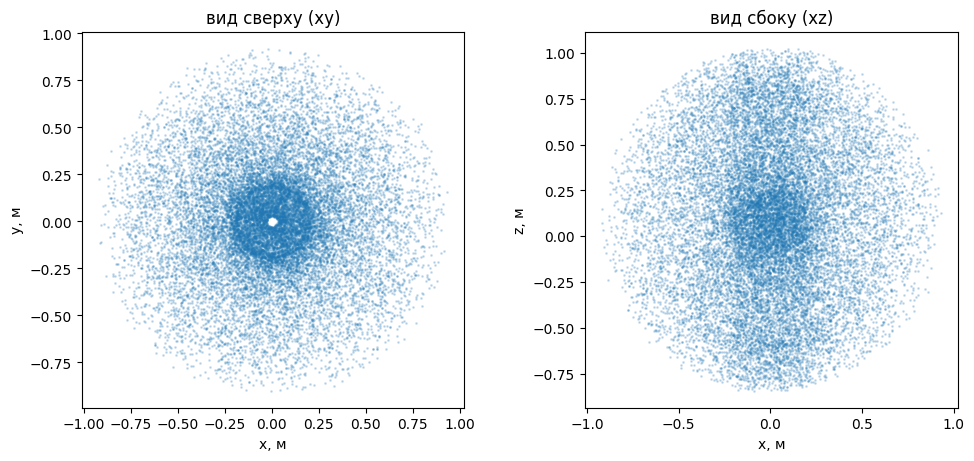

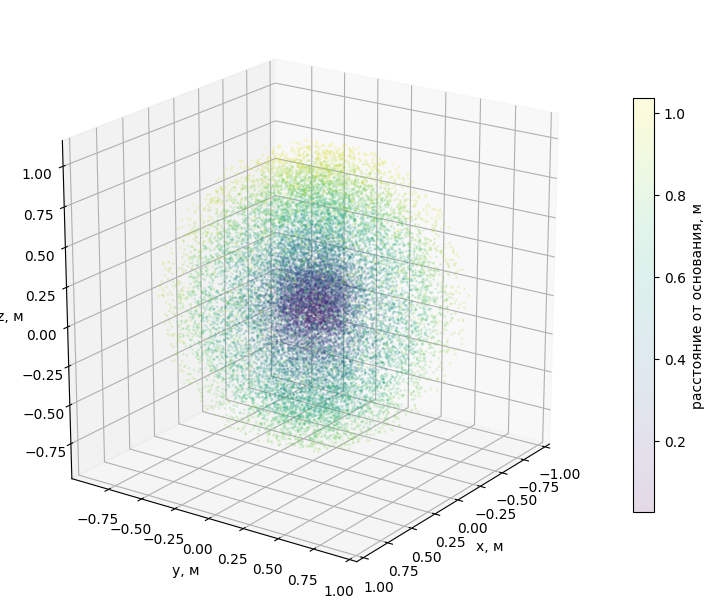

In [92]:
# ============================================================
# ЗАДАНИЕ 3. UR5: два пути прямой кинематики и компиляция
# ============================================================

# 1) Точная таблица DH для символьной части: у скрещиваний углы --
#    ТОЧНЫЕ sp.pi/2 (в таблице UR5 из первой ячейки -- числа np.pi/2).
#    sin(sp.pi/2) = 1 точно, а sin(np.pi/2) = 6.1e-17: SymPy не знает,
#    что это pi/2, и не может ничего упростить.
UR5_exact = [(0.0,      sp.pi / 2,  0.089159),
             (-0.425,   0,          0.0),
             (-0.39225, 0,          0.0),
             (0.0,      sp.pi / 2,  0.10915),
             (0.0,     -sp.pi / 2,  0.09465),
             (0.0,      0.0,        0.0823)]

# 2) Символы углов: 'q1:7' разворачивается в q1, q2, ..., q6.
q = sp.symbols('q1:7', real=True)

# 3) Символьная кинематика: произведение шести матриц DH вдоль цепи.
T_sym = sp.eye(4)                    # единичная матрица -- нейтральное начало
for (a, al, d), qi in zip(UR5_exact, q):
    T_sym = T_sym * dh(a, al, d, qi, lib=sp)
T_sym = sp.simplify(T_sym)           # sin(pi/2) -> 1, cos(pi/2) -> 0 и т.п.
print("операций в выражении (точные alpha):", sp.count_ops(T_sym))

# Для сравнения: та же кинематика, но alpha -- числа np.pi/2 из таблицы
# UR5. Приближённое число блокирует упрощения (см. метод. замечания).
T_float = sp.eye(4)
for (a, al, d), qi in zip(UR5, q):
    T_float = T_float * dh(a, al, d, qi, lib=sp)
print("операций при приближённых alpha:", sp.count_ops(T_float))

# 4) Численный путь: рукописный цикл по шести матрицам.
def ur5_fk(qs):
    """Прямая кинематика UR5 численным циклом (numpy)."""
    T = np.eye(4)
    for (a, al, d), th in zip(UR5, qs):     # таблица UR5 из первой ячейки
        T = T @ dh(a, al, d, th, lib=np)
    return T

# 5) Компиляция символьного выражения в численную функцию.
fk_lamb = sp.lambdify(q, T_sym, 'numpy')             # обычная компиляция
fk_cse = sp.lambdify(q, T_sym, 'numpy', cse=True)    # + общие подвыражения

# 6) Контроль: оба пути согласованы с точностью 1e-12.
max_diff = 0.0
for qs in rng.uniform(-np.pi, np.pi, size=(50, 6)):
    max_diff = max(max_diff, np.abs(ur5_fk(qs) - fk_cse(*qs)).max())
print("max |numpy-цикл - lambdify+cse| =", max_diff)

# 7) Замеры времени. Один запуск на микросекундах бессмыслен --
#    усредняем по тысячам вызовов (метод. замечания, п. 3.3).
def time_per_call(fn, configs):
    """Среднее время одного вызова fn, мс."""
    t0 = time.perf_counter()             # секундомер высокого разрешения
    for qs in configs:
        fn(qs)
    return (time.perf_counter() - t0) / len(configs) * 1000

cfg_slow = rng.uniform(-np.pi, np.pi, size=(300, 6))     # для медленного subs
cfg_fast = rng.uniform(-np.pi, np.pi, size=(10000, 6))   # для быстрых путей

t_subs = time_per_call(lambda qs: T_sym.subs(dict(zip(q, qs))).evalf(), cfg_slow)
t_lamb = time_per_call(lambda qs: fk_lamb(*qs), cfg_fast)
t_cse = time_per_call(lambda qs: fk_cse(*qs), cfg_fast)
t_np = time_per_call(ur5_fk, cfg_fast)

print(f"\n{'способ':<22}{'мс/вызов':>10}{'ускорение к subs':>20}")
for name, t in (('subs + evalf', t_subs), ('lambdify', t_lamb),
                ('lambdify + cse', t_cse), ('numpy-цикл', t_np)):
    print(f"{name:<22}{t:>10.4f}{t_subs / t:>19.0f}x")

# 8) Облако из 20000 положений схвата и максимальный вылет.
cfg_cloud = rng.uniform(-np.pi, np.pi, size=(20000, 6))
pts = np.array([fk_cse(*qs)[:3, 3] for qs in cfg_cloud])
reach = np.linalg.norm(pts, axis=1).max()
upper = sum(abs(a) for a, _, d in UR5_exact) + sum(abs(d) for a, _, d in UR5_exact)
a23 = abs(UR5_exact[1][0]) + abs(UR5_exact[2][0])
print("\nмаксимальный вылет:", reach)
print("оценка сверху (неравенство треугольника):", upper)
print("a2 + a3 =", a23)
print("контроль a2+a3 < вылет < оценка сверху:", a23 < reach < upper)

# 9) Облако: два вида -- сверху (xy) и сбоку (xz).
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
ax1.scatter(pts[:, 0], pts[:, 1], s=1, alpha=0.2)
ax1.set_title("вид сверху (xy)")
ax1.set_xlabel("x, м")
ax1.set_ylabel("y, м")
ax1.set_aspect('equal')
ax2.scatter(pts[:, 0], pts[:, 2], s=1, alpha=0.2)
ax2.set_title("вид сбоку (xz)")
ax2.set_xlabel("x, м")
ax2.set_ylabel("z, м")
ax2.set_aspect('equal')
plt.show()

# 10) Облако в объёме: 3D-график (mplot3d).
fig3 = plt.figure(figsize=(7.5, 6), constrained_layout=True)
ax3 = fig3.add_subplot(projection='3d')          # 3D-оси вместо плоских
p3d = ax3.scatter(pts[:, 0], pts[:, 1], pts[:, 2],
                  s=1, alpha=0.15, c=np.linalg.norm(pts, axis=1),
                  cmap='viridis')
ax3.set_xlabel("x, м")
ax3.set_ylabel("y, м")
ax3.set_zlabel("z, м")
ax3.set_aspect('equal')                          # шар не сплющится в эллипсоид
ax3.view_init(elev=20, azim=35)                  # откуда смотрим: углы в градусах
fig3.colorbar(p3d, ax=ax3, shrink=0.7, label="расстояние от основания, м")
plt.show()

## Задание 4. Рабочая зона плоского 2R и сходимость Монте-Карло

Для $l_1 = 0{,}5$, $l_2 = 0{,}35$ вычислите точную площадь кольца.
Затем оцените её методом Монте-Карло: бросайте точки в квадрат со стороной
$2(l_1{+}l_2)$ и считайте долю попавших в кольцо.

Для $N$ от $10^2$ до $10^6$ усредните ошибку по 30 независимым запускам, постройте
график в двойном логарифмическом масштабе и оцените наклон.

**Контроль.** Наклон должен получиться близким к $-0{,}5$.

**Вопросы для вывода:** почему точная площадь равна $4\pi l_1 l_2$? Во сколько раз
надо увеличить $N$, чтобы уменьшить ошибку вдвое? Зависит ли скорость сходимости
от размерности задачи?

In [ ]:
# TODO: задание 4

## Задание 5. Объём рабочей зоны UR5

Для шестиосевого манипулятора точной формулы нет. Оцените объём рабочей зоны
по облаку точек: разбейте пространство на воксели со стороной $h$ и умножьте число
занятых вокселей на $h^3$.

Посчитайте оценку при $h = 0{,}08$, $0{,}05$, $0{,}03$ м, а затем при фиксированном
$h = 0{,}05$ проследите, как оценка меняется с ростом числа выборок.

**Контроль.** Оценка должна расти с числом выборок.

**Вопросы для вывода:** почему оценка растёт с $N$ и не выходит на плато даже
при 20000 выборок? Почему она так сильно зависит от $h$? В какую сторону смещена
такая оценка и почему? Сколько примерно выборок нужно, чтобы заполнить все воксели
при $h = 0{,}05$?

In [ ]:
# TODO: задание 5

## Задание 6. Произведение экспонент и его эквивалентность DH

Реализуйте `exp_se3(S, theta)` — матричную экспоненту для винтовой оси.
Формула прямо обобщает Родрига из лекции 3:

$$e^{[S]\theta} = \begin{pmatrix} e^{[\omega]\theta} & G(\theta)\,v \\ 0 & 1\end{pmatrix},
\quad G(\theta) = I\theta + (1-\cos\theta)[\omega] + (\theta - \sin\theta)[\omega]^2 .$$

Задайте для плоского 3R матрицу $M$ нулевой конфигурации и три винтовые оси,
после чего сравните результат с DH-версией на 500 случайных конфигурациях.

**Контроль.** Расхождение на уровне машинной погрешности ($\sim 10^{-16}$).

**Вопрос для вывода:** в чём преимущество представления произведением экспонент
перед DH, если результат тот же?

In [ ]:
# TODO: задание 6

## Задание 7. Движение по последовательности конфигураций

Постройте функцию `arm_points(q)`, возвращающую координаты всех сочленений
плоского 3R. Задайте линейную интерполяцию между двумя конфигурациями по 60 шагам
и нарисуйте несколько промежуточных поз с нарастающей непрозрачностью, а поверх —
траекторию схвата.

**Вопрос для вывода:** траектория схвата при линейной интерполяции в конфигурационном
пространстве — прямая линия в рабочем пространстве? Почему?

In [ ]:
# TODO: задание 7

## Выводы

_Ответьте на все вопросы, отмеченные как «вопрос для вывода», приводя конкретные числа._

## Контрольные вопросы

1. Что такое конфигурационное пространство? Почему для цепи из $n$ вращательных
   сочленений это тор $T^n$, а не $\mathbb{R}^n$?
2. Почему прямая задача кинематики всегда разрешима однозначно, а обратная — нет?
3. Какой геометрический смысл у каждого из четырёх параметров DH?
4. Почему для перехода между соседними звеньями хватает четырёх чисел вместо шести?
5. В чём недостатки соглашения DH и что предлагает взамен представление
   произведением экспонент?
6. Запишите формулу винтовой оси $S = (\omega, v)$ для вращательного сочленения.
   Каков геометрический смысл вектора $v$?
7. Как связаны формула Родрига из лекции 3 и матричная экспонента для $se(3)$?
8. Что такое рабочая зона? Чему равна её площадь для плоского 2R-манипулятора?
9. Почему погрешность метода Монте-Карло убывает как $N^{-1/2}$ и не зависит
   от размерности?
10. Почему воксельная оценка объёма смещена вниз и как это исправить?